## DATASET OVERVIEW

#### Load Datasets

In [1]:
#Load datasets

from pathlib import Path
import pandas as pd

#Notebook lives in notebooks/, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT/ "data" / "raw"

#Check if Python finds the files
print(DATA_DIR)
print(sorted(p.name for p in DATA_DIR.rglob("*.csv")))

/Users/nganhoang/Desktop/DUNNHUMBY project/data/raw
['campaign_desc.csv', 'campaign_table.csv', 'causal_data.csv', 'coupon.csv', 'coupon_redempt.csv', 'hh_demographic.csv', 'product.csv', 'transaction_data.csv']


In [2]:
#Load every CSV into a dictionary-example:tables["transaction_data"]

tables = {p.stem: pd.read_csv(p) for p in DATA_DIR.rglob("*.csv")
          if p.stem != "causal_data"} #skil huge causal table for now

for name, df in tables.items():
    print(f"{name:20s} {df.shape}")

hh_demographic       (801, 8)
coupon               (124548, 3)
campaign_table       (7208, 3)
coupon_redempt       (2318, 4)
product              (92353, 7)
campaign_desc        (30, 4)
transaction_data     (2595732, 12)


In [3]:
transactions  = tables["transaction_data"]
demographics  = tables["hh_demographic"]
products      = tables["product"]
campaign_desc = tables["campaign_desc"]
campaign_tbl  = tables["campaign_table"]
coupons       = tables["coupon"]
redemptions   = tables["coupon_redempt"]

# Look at the exact column names first. Adjust the checks below if they differ
for name, df in tables.items():
    print(name, list(df.columns))


hh_demographic ['classification_1', 'classification_2', 'classification_3', 'HOMEOWNER_DESC', 'classification_5', 'classification_4', 'KID_CATEGORY_DESC', 'household_key']
coupon ['COUPON_UPC', 'PRODUCT_ID', 'CAMPAIGN']
campaign_table ['DESCRIPTION', 'household_key', 'CAMPAIGN']
coupon_redempt ['household_key', 'DAY', 'COUPON_UPC', 'CAMPAIGN']
product ['PRODUCT_ID', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT']
campaign_desc ['DESCRIPTION', 'CAMPAIGN', 'START_DAY', 'END_DAY']
transaction_data ['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC']


In [4]:
#Check meaning inference for "Demographics" column names
#Demographic fields are anonymized but ordinal. 
#Based on value ranges, classification_3 likely represents income bands (Level1 = lowest)

for col in demographics.columns.drop("household_key"):
    print(col, sorted(demographics[col].dropna().unique()))

classification_1 ['Age Group1', 'Age Group2', 'Age Group3', 'Age Group4', 'Age Group5', 'Age Group6']
classification_2 ['X', 'Y', 'Z']
classification_3 ['Level1', 'Level10', 'Level11', 'Level12', 'Level2', 'Level3', 'Level4', 'Level5', 'Level6', 'Level7', 'Level8', 'Level9']
HOMEOWNER_DESC ['Homeowner', 'Probable Owner', 'Probable Renter', 'Renter', 'Unknown']
classification_5 ['Group1', 'Group2', 'Group3', 'Group4', 'Group5', 'Group6']
classification_4 ['1', '2', '3', '4', '5+']
KID_CATEGORY_DESC ['1', '2', '3+', 'None/Unknown']


#### Check data integrity: keys check

In [5]:
#Check primary keys

def check_primary_key(df, cols, name):
    dupes = df.duplicated(subset=cols).sum()
    status = "Unique" if dupes == 0 else f"{dupes:,} duplicate rows"
    print(f"{name:15s} key {cols}: {status}")

check_primary_key(demographics,  ["household_key"],                      "demographics")
check_primary_key(products,      ["PRODUCT_ID"],                         "products")
check_primary_key(campaign_desc, ["CAMPAIGN"],                           "campaign_desc")
check_primary_key(campaign_tbl,  ["household_key", "CAMPAIGN"],          "campaign_tbl")
check_primary_key(coupons,       ["COUPON_UPC", "PRODUCT_ID", "CAMPAIGN"], "coupons")
check_primary_key(redemptions,   ["household_key", "COUPON_UPC", "DAY"], "redemptions")
check_primary_key(transactions,  ["BASKET_ID", "PRODUCT_ID"],            "transactions")


demographics    key ['household_key']: Unique
products        key ['PRODUCT_ID']: Unique
campaign_desc   key ['CAMPAIGN']: Unique
campaign_tbl    key ['household_key', 'CAMPAIGN']: Unique
coupons         key ['COUPON_UPC', 'PRODUCT_ID', 'CAMPAIGN']: 5,164 duplicate rows
redemptions     key ['household_key', 'COUPON_UPC', 'DAY']: 14 duplicate rows
transactions    key ['BASKET_ID', 'PRODUCT_ID']: Unique


In [6]:
#Check foreign keys

def check_foreign_key(child, child_col, parent, parent_col, label):
    child_vals = set(child[child_col].dropna().unique())
    parent_vals = set(parent[parent_col].dropna().unique())
    missing = child_vals - parent_vals
    pct = len(missing) / len(child_vals) * 100
    print(f"{label:45s} {len(missing):,} of {len(child_vals):,} unmatched ({pct:.1f}%)")


# Households
check_foreign_key(campaign_tbl, "household_key", transactions, "household_key", "campaign households -> transactions")
check_foreign_key(redemptions,  "household_key", transactions, "household_key", "redeeming households -> transactions")
check_foreign_key(demographics, "household_key", transactions, "household_key", "demographic households -> transactions")

# Products
check_foreign_key(transactions, "PRODUCT_ID", products, "PRODUCT_ID", "transaction products -> products")
check_foreign_key(coupons,      "PRODUCT_ID", products, "PRODUCT_ID", "coupon products -> products")

# Campaigns and coupons
check_foreign_key(campaign_tbl, "CAMPAIGN",   campaign_desc, "CAMPAIGN",   "campaign table -> campaign_desc")
check_foreign_key(redemptions,  "CAMPAIGN",   campaign_desc, "CAMPAIGN",   "redemptions -> campaign_desc")
check_foreign_key(redemptions,  "COUPON_UPC", coupons,       "COUPON_UPC", "redeemed coupons -> coupon table")

campaign households -> transactions           0 of 1,584 unmatched (0.0%)
redeeming households -> transactions          0 of 434 unmatched (0.0%)
demographic households -> transactions        0 of 801 unmatched (0.0%)
transaction products -> products              0 of 92,339 unmatched (0.0%)
coupon products -> products                   0 of 44,133 unmatched (0.0%)
campaign table -> campaign_desc               0 of 30 unmatched (0.0%)
redemptions -> campaign_desc                  0 of 30 unmatched (0.0%)
redeemed coupons -> coupon table              0 of 556 unmatched (0.0%)


In [7]:
# Coverage check

n_hh = transactions["household_key"].nunique()
print(f"Households in transactions:       {n_hh:,}")
print(f"Households with demographics:     {demographics['household_key'].nunique():,} "
      f"({demographics['household_key'].nunique()/n_hh:.0%})")
print(f"Households targeted by campaigns: {campaign_tbl['household_key'].nunique():,}")
print(f"Households that redeemed:         {redemptions['household_key'].nunique():,}")

Households in transactions:       2,500
Households with demographics:     801 (32%)
Households targeted by campaigns: 1,584
Households that redeemed:         434


**Summary key checks**
**Primary keys**
-  coupons table key ['COUPON_UPC', 'PRODUCT_ID', 'CAMPAIGN']: 5164 duplicate rows
- redemptions table key ['household_key', 'COUPON_UPC', 'DAY']: 14 duplicate rows

**Foreign keys**
- Foreign key 0% unmatched : the tables link cleanly

**Households coverage**
- Households in transactions:       2,500
- Households with demographics:     801 (32%)
- Households targeted by campaigns: 1,584
- Households that redeemed:         434

In [8]:
#COUPONS
"""
Key check uses all three columns, so these are exact copies of
the same coupon-product-campaign row. They add no information.
"""

print(coupons.duplicated().sum())
coupons = coupons.drop_duplicates()

tables["coupon"] = coupons

5164


In [9]:
#REDEMPTIONS
dupes = redemptions[redemptions.duplicated(subset=["household_key", "COUPON_UPC", "DAY"], keep=False)]
print(dupes.sort_values(["household_key", "COUPON_UPC", "DAY"]))
print("Exact copies:", redemptions.duplicated().sum())

      household_key  DAY   COUPON_UPC  CAMPAIGN
61               22  640  54850010033        18
62               22  640  54850010033        22
76               40  607  57410101082        18
77               40  607  57410101082        19
98               67  455  53800050033         8
99               67  455  53800050033         9
113              67  639  54850010033        18
114              67  639  54850010033        22
281             256  533  54100027032        13
282             256  533  54100027032        14
372             367  438  53800050033         8
373             367  438  53800050033         9
614             636  533  54100027032        13
615             636  533  54100027032        14
784             877  459  53800050033         8
785             877  459  53800050033         9
802             888  540  54100027032        13
803             888  540  54100027032        14
917             979  655  54850010033        22
918             979  655  54850010033   

In [10]:
#REDEMPTIONS
"""
14 duplicates aren't real duplicates: each pair is same household
redemptions under the same day, but different campaigns
- keep all rows for per-campaign analysis
- keep unique rows for total redemptions count 
"""

unique_redemptions = redemptions.drop_duplicates(subset=["household_key", "COUPON_UPC", "DAY"])

#### Data Health Check

In [11]:
#Missing values

for name, df in tables.items():
    missing = df.isna().sum()
    print(f"\n{name}:\n{missing[missing > 0] if missing.any() else 'No missing values'}")


hh_demographic:
No missing values

coupon:
No missing values

campaign_table:
No missing values

coupon_redempt:
No missing values

product:
No missing values

campaign_desc:
No missing values

transaction_data:
No missing values


In [12]:
#Exact duplicates
for name, df in tables.items():
    print(f"{name:20s} {df.duplicated().sum():,} exact duplicates")

hh_demographic       0 exact duplicates
coupon               0 exact duplicates
campaign_table       0 exact duplicates
coupon_redempt       0 exact duplicates
product              0 exact duplicates
campaign_desc        0 exact duplicates
transaction_data     0 exact duplicates


In [13]:
#Data types
#IDs should be INT, SALES_VALUE & discount columns should be float

for name, df in tables.items():
    print(f"\n{name}\n{df.dtypes}")


hh_demographic
classification_1     object
classification_2     object
classification_3     object
HOMEOWNER_DESC       object
classification_5     object
classification_4     object
KID_CATEGORY_DESC    object
household_key         int64
dtype: object

coupon
COUPON_UPC    int64
PRODUCT_ID    int64
CAMPAIGN      int64
dtype: object

campaign_table
DESCRIPTION      object
household_key     int64
CAMPAIGN          int64
dtype: object

coupon_redempt
household_key    int64
DAY              int64
COUPON_UPC       int64
CAMPAIGN         int64
dtype: object

product
PRODUCT_ID               int64
MANUFACTURER             int64
DEPARTMENT              object
BRAND                   object
COMMODITY_DESC          object
SUB_COMMODITY_DESC      object
CURR_SIZE_OF_PRODUCT    object
dtype: object

campaign_desc
DESCRIPTION    object
CAMPAIGN        int64
START_DAY       int64
END_DAY         int64
dtype: object

transaction_data
household_key          int64
BASKET_ID              int64
DAY    

In [14]:
#Odd values in transactions

t = transactions
print("SALES_VALUE <= 0:     ", (t["SALES_VALUE"] <= 0).sum())
print("QUANTITY == 0:        ", (t["QUANTITY"] == 0).sum())
print("QUANTITY > 100:       ", (t["QUANTITY"] > 100).sum())
print(t[["QUANTITY", "SALES_VALUE", "RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC"]].describe())


SALES_VALUE <= 0:      18850
QUANTITY == 0:         14466
QUANTITY > 100:        23136
           QUANTITY   SALES_VALUE   RETAIL_DISC   COUPON_DISC  \
count  2.595732e+06  2.595732e+06  2.595732e+06  2.595732e+06   
mean   1.004286e+02  3.104120e+00 -5.387054e-01 -1.641600e-02   
std    1.153436e+03  4.182274e+00  1.249191e+00  2.168410e-01   
min    0.000000e+00  0.000000e+00 -1.800000e+02 -5.593000e+01   
25%    1.000000e+00  1.290000e+00 -6.900000e-01  0.000000e+00   
50%    1.000000e+00  2.000000e+00 -1.000000e-02  0.000000e+00   
75%    1.000000e+00  3.490000e+00  0.000000e+00  0.000000e+00   
max    8.963800e+04  8.400000e+02  3.990000e+00  0.000000e+00   

       COUPON_MATCH_DISC  
count       2.595732e+06  
mean       -2.918564e-03  
std         3.969004e-02  
min        -7.700000e+00  
25%         0.000000e+00  
50%         0.000000e+00  
75%         0.000000e+00  
max         0.000000e+00  


DAY range:     1 - 711
WEEK_NO range: 1 - 102


<Axes: title={'center': 'Total weekly sales'}, xlabel='WEEK_NO'>

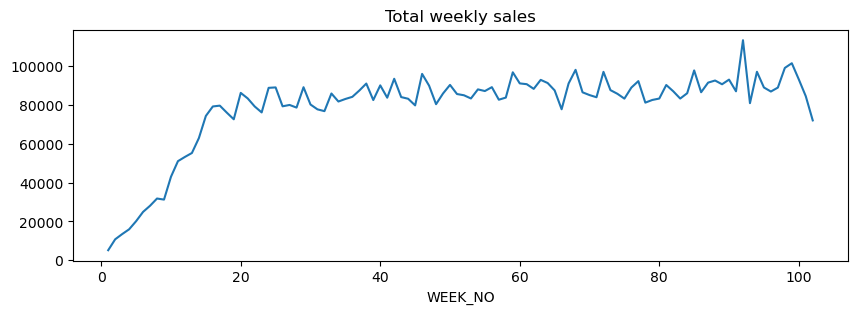

In [15]:
#Time range & activity

print("DAY range:    ", t["DAY"].min(), "-", t["DAY"].max())
print("WEEK_NO range:", t["WEEK_NO"].min(), "-", t["WEEK_NO"].max())

weekly = t.groupby("WEEK_NO")["SALES_VALUE"].sum()
weekly.plot(title="Total weekly sales", figsize=(10, 3))

In [16]:
# Unneeded products

# See which comodities have extreme quantities
t_prod = t.merge(products[["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC"]], on="PRODUCT_ID", how="left")
print(t_prod[t_prod["QUANTITY"] > 100]["COMMODITY_DESC"].value_counts().head(10))

# Look at department names to spot non-grocery items
print(products["DEPARTMENT"].value_counts())

COMMODITY_DESC
COUPON/MISC ITEMS    23129
FUEL                     6
CORN                     1
Name: count, dtype: int64
DEPARTMENT
GROCERY            39021
DRUG GM            31529
PRODUCE             3118
COSMETICS           3011
NUTRITION           2914
MEAT                2544
MEAT-PCKGD          2427
DELI                2354
PASTRY              2149
FLORAL               938
SEAFOOD-PCKGD        563
MISC. TRANS.         490
SPIRITS              377
SEAFOOD              369
GARDEN CENTER        128
RESTAURANT           102
MISC SALES TRAN       88
SALAD BAR             48
COUP/STR & MFG        39
TRAVEL & LEISUR       28
FROZEN GROCERY        23
KIOSK-GAS             16
                      15
CHEF SHOPPE           14
RX                     9
CNTRL/STORE SUP        4
DAIRY DELI             3
TOYS                   3
POSTAL CENTER          3
GM MERCH EXP           3
VIDEO RENTAL           3
AUTOMOTIVE             2
PHOTO                  2
VIDEO                  2
PROD-WHS SALES   

In [17]:
# Campaign sanity check

cd = campaign_desc
print("Start after end:", (cd["START_DAY"] > cd["END_DAY"]).sum())
print("Days outside data range:", ((cd["START_DAY"] < 1) | (cd["END_DAY"] > t["DAY"].max())).sum())
print(cd.groupby("DESCRIPTION")["CAMPAIGN"].count())          # campaigns per type
print((cd["END_DAY"] - cd["START_DAY"]).describe())           # campaign duration

# Does each campaign have the same type in both tables?
check = campaign_tbl[["CAMPAIGN", "DESCRIPTION"]].drop_duplicates().merge(
    cd[["CAMPAIGN", "DESCRIPTION"]], on="CAMPAIGN", suffixes=("_tbl", "_desc"))
print("Type mismatches:", (check["DESCRIPTION_tbl"] != check["DESCRIPTION_desc"]).sum())

Start after end: 0
Days outside data range: 1
DESCRIPTION
TypeA     5
TypeB    19
TypeC     6
Name: CAMPAIGN, dtype: int64
count     30.000000
mean      46.600000
std       24.856277
min       32.000000
25%       32.000000
50%       37.500000
75%       54.500000
max      161.000000
dtype: float64
Type mismatches: 0


In [18]:
# Demographic values

for col in demographics.columns.drop("household_key"):
    print(col, sorted(demographics[col].dropna().unique()))

classification_1 ['Age Group1', 'Age Group2', 'Age Group3', 'Age Group4', 'Age Group5', 'Age Group6']
classification_2 ['X', 'Y', 'Z']
classification_3 ['Level1', 'Level10', 'Level11', 'Level12', 'Level2', 'Level3', 'Level4', 'Level5', 'Level6', 'Level7', 'Level8', 'Level9']
HOMEOWNER_DESC ['Homeowner', 'Probable Owner', 'Probable Renter', 'Renter', 'Unknown']
classification_5 ['Group1', 'Group2', 'Group3', 'Group4', 'Group5', 'Group6']
classification_4 ['1', '2', '3', '4', '5+']
KID_CATEGORY_DESC ['1', '2', '3+', 'None/Unknown']


### CLEANING DATA

#### Quantity == 0 & sales = or > 0 | Quantity > 0 & sales = 0

In [19]:
# Quantity == 0 & sales = or > 0 | Quantity > 0 & sales = 0
both_zero = ((t["QUANTITY"] == 0) & (t["SALES_VALUE"] == 0)).sum()
qty0_sales_pos = ((t["QUANTITY"] == 0) & (t["SALES_VALUE"] > 0)).sum()
qty_pos_sales0 = ((t["QUANTITY"] > 0) & (t["SALES_VALUE"] == 0)).sum()

print(f"Qty 0 and sales 0: {both_zero}")
print(f"Qty 0 but sales > 0: {qty0_sales_pos}")
print(f"Sales 0 but Qty > 0: {qty_pos_sales0}")

# Drop rows where nothing was purchased (quantity 0 and sales 0)
before = len(t)
t = t[~((t["QUANTITY"] == 0) & (t["SALES_VALUE"] == 0))].copy()
print(f"Dropped {before - len(t):,} rows. Remaining: {len(t):,}")

Qty 0 and sales 0: 14399
Qty 0 but sales > 0: 67
Sales 0 but Qty > 0: 4451
Dropped 14,399 rows. Remaining: 2,581,333


#### Retail discounts > 0

In [20]:
# Retail discounts > 0
# Discounts should be zero or negative => discounts > 0 might be errors/adjustments

print("Positive RETAIL_DISC rows:", (t["RETAIL_DISC"] > 0).sum())

# If it's small number, keep these rows as they barely affect spending totals


Positive RETAIL_DISC rows: 19


#### MAX Quantity > 100 & MAX Sales values > $840 

In [21]:
# Sales value max = $840 while most items are cheap (median $2, 75% < $3.50)

print(t_prod.sort_values("SALES_VALUE", ascending=False)
      [["household_key", "PRODUCT_ID", "QUANTITY", "SALES_VALUE", "COMMODITY_DESC"]].head(10))

         household_key  PRODUCT_ID  QUANTITY  SALES_VALUE  \
1085442           1609    12484608         3       840.00   
2030766            346      948670         5       631.80   
655985             125     1089093         2       505.00   
1152895            374    13212959         1       499.99   
547657             125     1089093         1       455.00   
526495            2080     1089093         1       430.00   
3600                64     1089093         1       400.00   
2352647           2395     1089093         1       380.00   
1366400           1109    13506935         1       329.99   
807063            2032     9296877        25       324.75   

                   COMMODITY_DESC  
1085442         COUPON/MISC ITEMS  
2030766                   TICKETS  
655985   NO COMMODITY DESCRIPTION  
1152895    SPRING/SUMMER SEASONAL  
547657   NO COMMODITY DESCRIPTION  
526495   NO COMMODITY DESCRIPTION  
3600     NO COMMODITY DESCRIPTION  
2352647  NO COMMODITY DESCRIPTION  
1366

In [22]:
# PRODUCT_ID 1089093 is likely gift card/money orders with round amounts
# COMMODITY_DESC 'TICKETS' is likely event or lottery tickets, not grocery behavior

print(products[products["PRODUCT_ID"] == 1089093])

exclude_candidates = ["COUPON/MISC ITEMS", "TICKETS", "NO COMMODITY DESCRIPTION"]
t_prod = t.merge(products[["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC"]], on="PRODUCT_ID", how="left")
summary = (t_prod[t_prod["COMMODITY_DESC"].isin(exclude_candidates)]
           .groupby("COMMODITY_DESC")
           .agg(rows=("SALES_VALUE", "size"), spend=("SALES_VALUE", "sum")))
print(summary)
print(f"Share of total spend: {summary['spend'].sum() / t['SALES_VALUE'].sum():.1%}")


       PRODUCT_ID  MANUFACTURER    DEPARTMENT     BRAND  \
36327     1089093             2  MISC. TRANS.  National   

                 COMMODITY_DESC           SUB_COMMODITY_DESC  \
36327  NO COMMODITY DESCRIPTION  NO SUBCOMMODITY DESCRIPTION   

      CURR_SIZE_OF_PRODUCT  
36327                       
                           rows      spend
COMMODITY_DESC                            
COUPON/MISC ITEMS         27711  639878.56
NO COMMODITY DESCRIPTION   2292   10678.69
TICKETS                     715    8243.08
Share of total spend: 8.2%


In [23]:
misc = t_prod[t_prod["COMMODITY_DESC"] == "COUPON/MISC ITEMS"].merge(
    products[["PRODUCT_ID", "SUB_COMMODITY_DESC"]], on="PRODUCT_ID")
print(misc.groupby(["DEPARTMENT", "SUB_COMMODITY_DESC"])
          .agg(rows=("SALES_VALUE", "size"), spend=("SALES_VALUE", "sum"),
               max_qty=("QUANTITY", "max"))
          .sort_values("spend", ascending=False).head(10))

                                                 rows      spend  max_qty
DEPARTMENT      SUB_COMMODITY_DESC                                       
KIOSK-GAS       GASOLINE-REG UNLEADED           20271  514685.72    89638
MISC SALES TRAN GASOLINE-REG UNLEADED            2903   89734.98    85055
                ELECTRONIC GIFT CARDS ACTIVATI    435    8608.04        8
                MEAT SUPPLIES                     946    5109.09        7
                OUTSIDE VENDORS GIFT CARDS        112    4166.64        9
                MISCELLANEOUS H & B AIDS          651    3567.78        9
GROCERY         MISC SALES TRANS                 1100    3326.26       27
MISC SALES TRAN ELECTRONIC GIFT CARDS REFRESH      35    2701.40        1
                MASTERCARD GIFT CARD               35    1817.12        2
                PRODUCE DEPT KEY RING             677    1626.49       11


**COUPON/MISC ITEMS CHECK**

- COUPON/MISC ITEMS is mostly fuel
- Gasoline: 20,271 + 2,903 rows, about $604K, 94% of this commodity’s spend
- Max quantity 89,638: that’s the source of quantity > 100 outliers
- The rest: gift cards, key rings, misc sales entries, all non-grocery

**Decision: exclude all three commodities (8.2% of spend).**

- Fuel, tickets, and misc transactions don’t reflect grocery shopping behavior, which is what the campaigns target.
- Fuel spend swings with gas prices and would distort before/after lift comparisons.
- 8.2% is a reasonable share to remove when it’s clearly non-grocery.

Limitation: A few small rows (“meat supplies,” “misc H&B aids”) might be real items, but together they’re about $9K out of millions, so excluding them doesn’t change the results and keeps the rule simple.


In [24]:
exclude = ["COUPON/MISC ITEMS", "TICKETS", "NO COMMODITY DESCRIPTION"]

before_rows, before_spend = len(t), t["SALES_VALUE"].sum()

t = t[~t["PRODUCT_ID"].isin(products.loc[products["COMMODITY_DESC"].isin(exclude), "PRODUCT_ID"])].copy()

print(f"Removed {before_rows - len(t):,} rows and ${before_spend - t['SALES_VALUE'].sum():,.0f} spend")
print("Rows with QUANTITY > 100 left:", (t["QUANTITY"] > 100).sum())
print("Max quantity now:", t["QUANTITY"].max())

Removed 30,718 rows and $658,800 spend
Rows with QUANTITY > 100 left: 7
Max quantity now: 30080


In [25]:
odd = t[t["QUANTITY"] > 100].merge(
    products[["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]], on="PRODUCT_ID")
print(odd[["household_key", "PRODUCT_ID", "QUANTITY", "SALES_VALUE",
           "DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]])

   household_key  PRODUCT_ID  QUANTITY  SALES_VALUE DEPARTMENT COMMODITY_DESC  \
0            125     5716076     17630        40.00  KIOSK-GAS           FUEL   
1           1959     5716076     30080        86.01  KIOSK-GAS           FUEL   
2            890      911878       144        24.00    PRODUCE           CORN   
3           2129      731106     17863        41.60  KIOSK-GAS           FUEL   
4           2129      731106     10393        24.00  KIOSK-GAS           FUEL   
5           1237      731106     19692        45.47  KIOSK-GAS           FUEL   
6           1237      731106     22177        51.21  KIOSK-GAS           FUEL   

      SUB_COMMODITY_DESC  
0  GASOLINE-REG UNLEADED  
1  GASOLINE-REG UNLEADED  
2             CORN WHITE  
3  GASOLINE-REG UNLEADED  
4  GASOLINE-REG UNLEADED  
5  GASOLINE-REG UNLEADED  
6  GASOLINE-REG UNLEADED  


In [26]:
# Drop all remaining fuel: KIOSK-GAS department, or any gasoline sub-commodity
# Dropped remaining fuel (KIOSK-GAS department and any gasoline sub-commodity outside COUPON/MISC ITEMS).
# No quantity outliers remain.


fuel_ids = products.loc[
    (products["DEPARTMENT"] == "KIOSK-GAS") |
    (products["SUB_COMMODITY_DESC"].str.contains("GASOLINE", case=False, na=False)),
    "PRODUCT_ID"]

before_rows, before_spend = len(t), t["SALES_VALUE"].sum()
t = t[~t["PRODUCT_ID"].isin(fuel_ids)].copy()

print(f"Dropped {before_rows - len(t):,} rows and ${before_spend - t['SALES_VALUE'].sum():,.0f} spend")
print("Rows with QUANTITY > 100 left:", (t["QUANTITY"] > 100).sum())
print("Max quantity now:", t["QUANTITY"].max())

Dropped 1,788 rows and $29,537 spend
Rows with QUANTITY > 100 left: 1
Max quantity now: 144


In [27]:
# Quick sanity check for 1 row with quantity > 100
print(t[t["QUANTITY"] > 100].merge(products[["PRODUCT_ID", "COMMODITY_DESC"]], on="PRODUCT_ID")
      [["QUANTITY", "SALES_VALUE", "COMMODITY_DESC"]])

   QUANTITY  SALES_VALUE COMMODITY_DESC
0       144         24.0           CORN


**DECISION LOGS**
- Removed 14,399 rows with quantity 0 and sales 0. Kept 67 rows with quantity 0 but sales above 0, and 4,451 zero-sales rows with quantity above 0 (free items).
- Excluded non-grocery items: COUPON/MISC ITEMS (about 94% gasoline), TICKETS, NO COMMODITY DESCRIPTION, plus remaining fuel (KIOSK-GAS, gasoline sub-commodities). About 8–9% of spend removed. No quantity outliers remain.
- Spend is measured with SALES_VALUE. Average quantity isn’t used.

#### Time range & activity 


<Axes: title={'center': 'Active households per week'}, xlabel='WEEK_NO'>

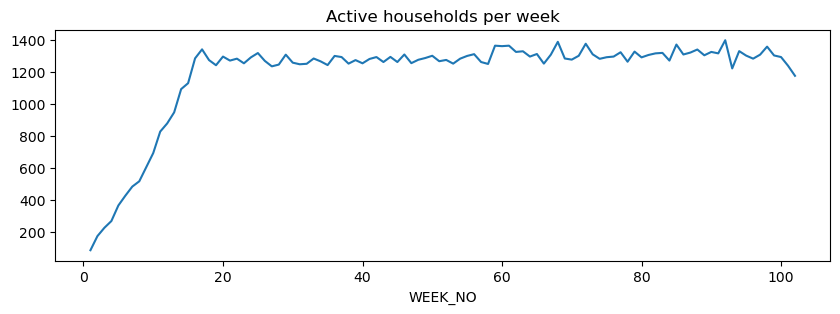

In [28]:
# Active households per week

t.groupby("WEEK_NO")["household_key"].nunique().plot(title="Active households per week", figsize=(10, 3))

Week 1 to 16 saw sales climb + active housholds per week
=> Panel filling up as households start being tracked - not real growth

In [29]:
cd = campaign_desc.copy()
cd["start_week"] = (cd["START_DAY"] // 7) + 1
cd["end_week"]   = (cd["END_DAY"] // 7) + 1
cd["baseline_ok"] = cd["start_week"] - 8 >= 17     # 8-week baseline fully after ramp-up
cd["post_ok"]     = cd["end_week"] + 8 <= 100      # 8-week post period before data tails off
print(cd.sort_values("START_DAY")[["CAMPAIGN", "DESCRIPTION", "start_week", "end_week", "baseline_ok", "post_ok"]])

    CAMPAIGN DESCRIPTION  start_week  end_week  baseline_ok  post_ok
29        26       TypeA          33        38         True     True
28        27       TypeC          34        43         True     True
27        28       TypeB          38        46         True     True
26        29       TypeB          41        48         True     True
25        30       TypeA          47        53         True     True
23         1       TypeB          50        55         True     True
24         2       TypeB          51        55         True     True
20         3       TypeC          51        59         True     True
22         4       TypeB          54        58         True     True
21         5       TypeB          54        59         True     True
19         6       TypeC          57        61         True     True
18         7       TypeB          57        62         True     True
17         8       TypeA          59        66         True     True
16         9       TypeB          

- Campaign 15 is unusual. It’s TypeC and runs weeks 79–102, about 23 weeks, far longer than the others (4–10 weeks). It overlaps almost every late campaign.

- Campaigns overlap heavily, especially in weeks 50–62. Campaigns 1–7 all run in that stretch. A household in campaign 4 may also be in 2, 3, or 5 at the same time, so it's hard to tell which campaign caused a change.

In [30]:
# How oftern a household is in overlap campaigns

ct = campaign_tbl.merge(cd[["CAMPAIGN", "start_week", "end_week"]], on="CAMPAIGN")

pairs = ct.merge(ct, on="household_key", suffixes=("", "_other"))
pairs = pairs[pairs["CAMPAIGN"] != pairs["CAMPAIGN_other"]]

overlap = pairs[(pairs["start_week_other"] <= pairs["end_week"]) &
                (pairs["end_week_other"] >= pairs["start_week"])]

ct["has_overlap"] = ct.set_index(["household_key", "CAMPAIGN"]).index.isin(
    overlap.set_index(["household_key", "CAMPAIGN"]).index)

print(f"Household-campaign rows with an overlapping campaign: {ct['has_overlap'].mean():.0%}")
print(ct.groupby("CAMPAIGN")["has_overlap"].mean().round(2))

Household-campaign rows with an overlapping campaign: 59%
CAMPAIGN
1     0.85
2     0.75
3     1.00
4     0.44
5     0.95
6     0.94
7     0.92
8     0.37
9     0.78
10    0.63
11    0.93
12    0.91
13    0.41
14    0.98
15    1.00
16    0.93
17    0.97
18    0.55
19    0.87
20    0.94
21    0.88
22    0.93
23    0.72
24    0.59
25    0.66
26    0.07
27    0.92
28    0.88
29    0.33
30    0.25
Name: has_overlap, dtype: float64


- Low overlap, the cleanest campaigns: 26 (7%), 30 (25%), 29 (33%), 8 (37%), 13 (41%), 4 (44%). Four of those six are TypeA.
- TypeC always overlaps: 92–100% for every TypeC campaign, so its effect can never be cleanly separated.
- Most TypeB campaigns overlap: 60–97%, except 29 and 4.

In [31]:
#Add 'has_overlap' and 'n_concurrent' columns
conc = overlap.groupby(["household_key", "CAMPAIGN"])["CAMPAIGN_other"].nunique()
ct["n_concurrent"] = ct.set_index(["household_key", "CAMPAIGN"]).index.map(conc).fillna(0).astype(int)
print(ct["n_concurrent"].value_counts().sort_index())

n_concurrent
0    2929
1    2512
2    1192
3     442
4     109
5      21
6       2
7       1
Name: count, dtype: int64


**DECISION LOGS**

Time window

Weeks 1–16 are a panel ramp-up and weeks 101–102 a tail-off. The analysis window is weeks 17–100.

Campaigns

- All 30 campaigns have a clean 8-week baseline.
8-week post window: 23 campaigns eligible for BQ2 (5 A, 14 B, 4 C). Excluded: 15, 20–25.
- Campaign 15 (TypeC, 23 weeks, 100% overlap) is profiled in 1a only and excluded from BQ1 and BQ2.
- 59% of household-campaign rows overlap another campaign. Kept and flagged (has_overlap, n_concurrent). Lift is validated on the non-overlapping subset. Comparison groups exclude households in any campaign during the window.
- TypeC overlaps 92–100%, so results are reported with caution. Low-overlap campaigns (26, 30, 29, 8, 13, 4) are the cleanest case studies.

#### Demographics

In [32]:
demo = demographics.rename(columns={
    "classification_1": "age_group",
    "classification_2": "marital_xyz",
    "classification_3": "income_level",
    "classification_4": "hh_size",
    "classification_5": "hh_comp_group",
})

order = {
    "age_group":    [f"Age Group{i}" for i in range(1, 7)],
    "income_level": [f"Level{i}" for i in range(1, 13)],
    "hh_size":      ["1", "2", "3", "4", "5+"],
    "hh_comp_group":[f"Group{i}" for i in range(1, 7)],
    "KID_CATEGORY_DESC": ["None/Unknown", "1", "2", "3+"],
    "HOMEOWNER_DESC": ["Renter", "Probable Renter", "Probable Owner", "Homeowner", "Unknown"],
}
for col, levels in order.items():
    demo[col] = pd.Categorical(demo[col], categories=levels, ordered=True)

# Group sizes, to spot tiny groups
for col in demo.columns.drop("household_key"):
    print(f"\n{col}\n{demo[col].value_counts(sort=False)}")


age_group
age_group
Age Group1     46
Age Group2    142
Age Group3    194
Age Group4    288
Age Group5     59
Age Group6     72
Name: count, dtype: int64

marital_xyz
marital_xyz
X    340
Y    344
Z    117
Name: count, dtype: int64

income_level
income_level
Level1      61
Level2      74
Level3      77
Level4     172
Level5     192
Level6      96
Level7      34
Level8      38
Level9      30
Level10     11
Level11      5
Level12     11
Name: count, dtype: int64

HOMEOWNER_DESC
HOMEOWNER_DESC
Renter              42
Probable Renter     11
Probable Owner      11
Homeowner          504
Unknown            233
Name: count, dtype: int64

hh_comp_group
hh_comp_group
Group1     47
Group2     95
Group3    144
Group4    187
Group5    255
Group6     73
Name: count, dtype: int64

hh_size
hh_size
1     255
2     318
3     109
4      53
5+     66
Name: count, dtype: int64

KID_CATEGORY_DESC
KID_CATEGORY_DESC
None/Unknown    558
1               114
2                60
3+               69
Name: count, 

In [33]:
# Merge small income groups for comparision

# Income bands
band_map = {**{f"Level{i}": "Low" for i in [1, 2, 3]},
            **{f"Level{i}": "Lower-middle" for i in [4, 5]},
            **{f"Level{i}": "Upper-middle" for i in [6, 7, 8]},
            **{f"Level{i}": "High" for i in [9, 10, 11, 12]}}
demo["income_band"] = pd.Categorical(
    demo["income_level"].astype(str).map(band_map),
    categories=["Low", "Lower-middle", "Upper-middle", "High"], ordered=True)

# Homeowner merge
demo["homeowner"] = pd.Categorical(
    demo["HOMEOWNER_DESC"].astype(str).replace({"Probable Renter": "Renter", "Probable Owner": "Homeowner"}),
    categories=["Renter", "Homeowner", "Unknown"])

print(demo["income_band"].value_counts(sort=False))
print(demo["homeowner"].value_counts(sort=False))

income_band
Low             212
Lower-middle    364
Upper-middle    168
High             57
Name: count, dtype: int64
homeowner
Renter        53
Homeowner    515
Unknown      233
Name: count, dtype: int64


**Demographics: log**
- 801 of 2,500 households (32%), used for segment profiling only
- Values match the user guide. Age is confirmed from its labels, and the other fields are inferred from value ranges
- Ordinal fields are set as ordered categories (fixes Level10 sorting before Level2)
- Income: 12 levels grouped into 4 bands (Low 1–3, Lower-middle 4–5, Upper-middle 6–8, High 9–12), since Levels 10–12 have only 5–11 households each
- Homeowner: Probable Renter and Probable Owner (11 each) merged into Renter and Homeowner
- Original columns kept alongside the merged versions

**Things to note**
- Homeowner "Unknown" is 233 households (29%), so comparisons rest on about 570
- Kids "None/Unknown" (558) mixes no kids with unknown, so read it as "no kids reported"
- The High income band is small (57 households), so treat its results as indicative

#### Finalize Tables, Flah Campaign Eligibility

In [34]:
# Flag campaign table with eligibility flag

cd["bq1_eligible"] = cd["CAMPAIGN"] != 15                    # campaign 15 excluded from lift
cd["bq2_eligible"] = cd["post_ok"] & (cd["CAMPAIGN"] != 15)  # full 8-week post window

print(cd.groupby("DESCRIPTION")[["bq1_eligible", "bq2_eligible"]].sum())

             bq1_eligible  bq2_eligible
DESCRIPTION                            
TypeA                   5             5
TypeB                  19            14
TypeC                   5             4


In [35]:
hh_campaign = ct.copy()

In [36]:
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

clean_tables = {
    "transactions_clean": t,            # zero rows, non-grocery, and fuel removed
    "coupons_clean":      coupons,      # exact duplicates removed
    "redemptions_clean":  redemptions,  # all rows kept (dedupe on household, coupon, day for totals)
    "campaigns_clean":    cd,           # start/end weeks + eligibility flags
    "hh_campaign":        hh_campaign,  # household x campaign, with has_overlap and n_concurrent
    "demographics_clean": demo,         # renamed columns, income bands, merged homeowner
    "products":           products,     # unchanged, used for joins
}

for name, df in clean_tables.items():
    df.to_csv(CLEAN_DIR / f"{name}.csv", index=False)
    print(f"Saved {name:20s} {df.shape}")

Saved transactions_clean   (2548827, 12)
Saved coupons_clean        (119384, 3)
Saved redemptions_clean    (2318, 4)
Saved campaigns_clean      (30, 10)
Saved hh_campaign          (7208, 7)
Saved demographics_clean   (801, 10)
Saved products             (92353, 7)


In [37]:
print(f"Transactions: {len(transactions):,} raw -> {len(t):,} clean "
      f"({1 - len(t)/len(transactions):.1%} removed)")
print(f"Spend: ${transactions['SALES_VALUE'].sum():,.0f} raw -> ${t['SALES_VALUE'].sum():,.0f} clean")
print("Households still in transactions:", t["household_key"].nunique())

Transactions: 2,595,732 raw -> 2,548,827 clean (1.8% removed)
Spend: $8,057,463 raw -> $7,369,126 clean
Households still in transactions: 2500


#### Metrics Definition
**Metric definitions**

| Metric | Definition |
|---|---|
| **Spend** | Sum of `SALES_VALUE` |
| **Trips** | Number of unique `BASKET_ID` |
| **Basket size** | Spend ÷ trips |
| **Baseline window** | `START_DAY − 56` to `START_DAY − 1` (8 weeks) |
| **Campaign window** | `START_DAY` to `END_DAY` |
| **Post window** | `END_DAY + 1` to `END_DAY + 56` (8 weeks) |
| **Weekly averages** | Window totals ÷ number of weeks in the window (campaign lengths differ) |
| **Full-price repurchase** | Later purchase of a coupon product with `RETAIL_DISC == 0` and `COUPON_DISC == 0` |
| **Drop-off** | Post-window weekly spend below 80% of baseline weekly spend |

*Windows are defined in days because `WEEK_NO` differs from `DAY // 7 + 1` for 14% of rows. Weeks are used only for trend charts.*

In [38]:
t["week"] = t["DAY"] // 7 + 1
print((t["week"] != t["WEEK_NO"]).mean())

0.13959715586816995


In [39]:
#Recheck baseline eligibility flags
cd["baseline_ok_days"] = cd["START_DAY"] - 56 >= 113
cd["post_ok_days"]     = cd["END_DAY"] + 56 <= 700
print((cd["baseline_ok_days"] != cd["baseline_ok"]).sum(), "baseline flags changed")
print((cd["post_ok_days"] != cd["post_ok"]).sum(), "post flags changed")

0 baseline flags changed
0 post flags changed
